# 02. Data Preparation & Feature Representation

## Student Social Profile Segmentation Using Clustering

Notebook ini merupakan tahap kedua dari alur kerja proyek **Segmentasi Profil Sosial Siswa**. Berdasarkan hasil temuan dan rekomendasi dari tahap *Exploratory Data Analysis* (`01_eda.ipynb`), tahap data preparation ini berfokus pada penanganan anomali kualitas data, pembersihan atribut profil, pemisahan data profil vs fitur minat, penanganan profil tanpa minat (*all-zero*), serta rekayasa dan standardisasi dua representasi fitur minat utama yang akan diuji pada tahap pemodelan clustering (`03_model_development.ipynb`).

## 1. Setup & Inisialisasi Environment

Memuat library yang diperlukan untuk manipulasi data, rekayasa fitur, penskalaan numerik, dan visualisasi, serta mendefinisikan struktur direktori untuk keluaran preprocessing.

In [1]:
import os
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from sklearn.preprocessing import StandardScaler
import joblib

from IPython.display import display

# Konfigurasi tampilan Pandas
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.4f}".format)

# Konfigurasi visualisasi Seaborn & Matplotlib
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams["figure.titlesize"] = 14
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

# Penentuan path dataset dan folder output
PROJECT_ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA_PATH = PROJECT_ROOT / "data" / "Clustering_Marketing.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
PREPROC_DIR = OUTPUT_DIR / "preprocessing"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"

# Buat direktori output jika belum tersedia
PREPROC_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Environment setup berhasil.")
print(f"Dataset path: {DATA_PATH.resolve()}")
print(f"Preprocessing output: {PREPROC_DIR.resolve()}")
print(f"Figures output: {FIGURE_DIR.resolve()}")

Environment setup berhasil.
Dataset path: C:\Users\boyze\OneDrive\Desktop\ML\Student-Social-Profile-Segmentation-Using-Clustering\data\Clustering_Marketing.csv
Preprocessing output: C:\Users\boyze\OneDrive\Desktop\ML\Student-Social-Profile-Segmentation-Using-Clustering\outputs\preprocessing
Figures output: C:\Users\boyze\OneDrive\Desktop\ML\Student-Social-Profile-Segmentation-Using-Clustering\outputs\figures


## 2. Pemuatan Dataset & Verifikasi Integritas Data

Memuat file dataset `Clustering_Marketing.csv` dan memverifikasi integritas baris, kolom, dan tipe data awal.

In [2]:
# Memuat dataset
df = pd.read_csv(DATA_PATH)

print("Dataset berhasil dimuat.")
print(f"Dimensi dataset awal: {df.shape[0]:,} baris x {df.shape[1]} kolom")

# Menampilkan 5 baris pertama
display(df.head())

Dataset berhasil dimuat.
Dimensi dataset awal: 15,000 baris x 40 kolom


,gradyear,gender,age,NumberOffriends,basketball,football,soccer,softball,volleyball,swimming,cheerleading,baseball,tennis,sports,cute,sex,sexy,hot,kissed,dance,band,marching,music,rock,god,church,jesus,bible,hair,dress,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
0,2007,NaN,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2007,F,17.41,49,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
2,2007,F,17.511,41,0,0,0,0,0,0,0,1,0,0,0,3,0,0,0,0,0,0,1,2,0,1,0,0,4,0,0,1,0,0,0,0,0,0,1,1
3,2006,F,NaN,36,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,2008,F,16.657,1,0,0,0,0,0,1,0,0,3,0,6,0,2,0,0,0,0,0,1,0,1,1,0,0,5,0,0,0,0,3,0,0,0,0,0,0


In [3]:
# Verifikasi ringkasan tipe data dan keberadaan missing values awal
data_summary = pd.DataFrame({
    "Tipe Data": df.dtypes,
    "Jumlah Nilai Hilang": df.isna().sum(),
    "Persentase Hilang (%)": (df.isna().sum() / len(df) * 100).round(2),
    "Jumlah Unik": df.nunique()
})

display(data_summary.head(10))

,Tipe Data,Jumlah Nilai Hilang,Persentase Hilang (%),Jumlah Unik
gradyear,int64,0,0.0000,4
gender,object,1337,8.9100,2
age,object,2496,16.6400,1906
NumberOffriends,int64,0,0.0000,236
basketball,int64,0,0.0000,13
football,int64,0,0.0000,10
soccer,int64,0,0.0000,17
softball,int64,0,0.0000,16
volleyball,int64,0,0.0000,13
swimming,int64,0,0.0000,11


## 3. Pemisahan Fitur Profil vs Fitur Minat (Clustering Space)

Berdasarkan tinjauan metodologi clustering:
- **36 Fitur Minat (Interest Features):** Merupakan frekuensi kemunculan kata kunci minat siswa (non-negative integers). Fitur-fitur ini merupakan **input utama (clustering space)** yang akan dikelompokkan oleh algoritma clustering.
- **4 Fitur Profil Siswa (Profile Attributes):** `gradyear`, `gender`, `age`, dan `NumberOffriends`. Fitur-fitur ini sengaja **tidak disertakan sebagai variabel input clustering**, melainkan disimpan sebagai variabel eksternal untuk keperluan profiling, interpretasi segmen, dan validasi bisnis hasil cluster.

Pencampuran data demografis ke dalam metrik jarak clustering berbasis minat dapat mendistorsi pembentukan klaster karena perbedaan skala, unit pengukuran, dan tujuan segmentasi.

In [4]:
# Mendefinisikan kelompok fitur
PROFILE_COLS = ["gradyear", "gender", "age", "NumberOffriends"]
INTEREST_COLS = [c for c in df.columns if c not in PROFILE_COLS]

print(f"Jumlah Fitur Profil: {len(PROFILE_COLS)} kolom -> {PROFILE_COLS}")
print(f"Jumlah Fitur Minat : {len(INTEREST_COLS)} kolom")

# Memisahkan dataframe profil dan matriks fitur minat
df_profiles = df[PROFILE_COLS].copy()
X_interest_raw = df[INTEREST_COLS].copy()

# Verifikasi integritas pemisahan
assert len(PROFILE_COLS) + len(INTEREST_COLS) == df.shape[1], "Pemisahan kolom tidak lengkap!"
print(f"Pemisahan berhasil: df_profiles {df_profiles.shape}, X_interest_raw {X_interest_raw.shape}")

Jumlah Fitur Profil: 4 kolom -> ['gradyear', 'gender', 'age', 'NumberOffriends']
Jumlah Fitur Minat : 36 kolom
Pemisahan berhasil: df_profiles (15000, 4), X_interest_raw (15000, 36)


## 4. Pembersihan & Imputasi Fitur Profil Siswa

Pada tahap EDA, ditemukan beberapa masalah kualitas data pada fitur profil siswa:
1. `gender`: Mengandung 1.337 missing values (8,91%).
   - **Tindakan:** Missing value diimputasi dengan kategori `"Unknown"` agar seluruh observasi tetap memiliki label gender yang terdefinisi.
2. `age`: Mengandung 2.496 missing values (16,64%), 276 teks tanggal lokal Jerman (misal `"16. Jun"`), dan 153 nilai di luar batas usia wajar siswa (13–25 tahun), termasuk nilai ekstrem >100 tahun.
   - **Tindakan:**
     - Mengonversi seluruh nilai ke format numerik (`errors='coerce'`), mengubah string non-numerik menjadi `NaN`.
     - Menyaring nilai usia di luar interval wajar [13, 25] menjadi `NaN` sebagai kolom `age_clean`.
     - Memberikan opsi imputasi presisi tinggi: EDA membuktikan bahwa median usia per angkatan (`gradyear`) sangat konsisten terpaut tepat ~1 tahun (2006: 18.68, 2007: 17.70, 2008: 16.74, 2009: 15.79). Oleh karena itu, dibuat kolom `age_imputed` yang mengisi `NaN` dengan median usia per angkatan masing-masing.
3. `gradyear` & `NumberOffriends`:
   - Diverifikasi tipe datanya, memastikan tidak terdapat nilai hilang atau nilai negatif.

In [5]:
# 1. Pembersihan Gender
df_profiles_clean = pd.DataFrame(index=df.index)
df_profiles_clean["gradyear"] = df_profiles["gradyear"].astype(int)
df_profiles_clean["gender_raw"] = df_profiles["gender"]
df_profiles_clean["gender_clean"] = df_profiles["gender"].fillna("Unknown").astype(str)

# 2. Pembersihan & Imputasi Usia (Age)
age_numeric = pd.to_numeric(df_profiles["age"], errors="coerce")
valid_age_mask = age_numeric.between(13, 25)
df_profiles_clean["age_clean"] = np.where(valid_age_mask, age_numeric, np.nan)

# Menghitung median usia per gradyear dari data valid
median_age_per_gradyear = df_profiles_clean.groupby("gradyear")["age_clean"].transform("median")
df_profiles_clean["age_imputed"] = df_profiles_clean["age_clean"].fillna(median_age_per_gradyear)

# 3. Pembersihan NumberOffriends
friends_numeric = pd.to_numeric(df_profiles["NumberOffriends"], errors="coerce").fillna(0)
friends_numeric = np.maximum(friends_numeric, 0).astype(int)
df_profiles_clean["NumberOffriends"] = friends_numeric

# Menampilkan statistik profil sebelum vs sesudah pembersihan
print("Statistik Fitur Profil Setelah Pembersihan:")
display(df_profiles_clean[["gradyear", "gender_clean", "age_clean", "age_imputed", "NumberOffriends"]].describe(include="all"))

Statistik Fitur Profil Setelah Pembersihan:


,gradyear,gender_clean,age_clean,age_imputed,NumberOffriends
count,15000.0000,15000,12075.0000,15000.0000,15000.0000
unique,NaN,3,NaN,NaN,NaN
top,NaN,F,NaN,NaN,NaN
freq,NaN,11057,NaN,NaN,NaN
mean,2007.4969,NaN,17.2779,17.2515,29.8345
std,1.1165,NaN,1.1824,1.1639,35.3866
min,2006.0000,NaN,13.0270,13.0270,0.0000
25%,2006.0000,NaN,16.3260,16.3040,3.0000
50%,2008.0000,NaN,17.2810,17.2480,20.0000
75%,2008.0000,NaN,18.2420,18.2200,44.0000


In [6]:
# Verifikasi distribusi kategori gender setelah pembersihan
gender_dist = df_profiles_clean["gender_clean"].value_counts(dropna=False).reset_index()
gender_dist.columns = ["Gender", "Jumlah Profil"]
gender_dist["Persentase (%)"] = (gender_dist["Jumlah Profil"] / len(df_profiles_clean) * 100).round(2)
display(gender_dist)

# Verifikasi median usia per angkatan yang digunakan untuk imputasi
age_by_gradyear = df_profiles_clean.groupby("gradyear")[["age_clean", "age_imputed"]].agg(["count", "mean", "median", "std"])
display(age_by_gradyear)

,Gender,Jumlah Profil,Persentase (%)
0,F,11057,73.7100
1,M,2606,17.3700
2,Unknown,1337,8.9100


age_clean                        age_imputed                       
             count    mean  median    std       count    mean  median    std
gradyear                                                                    
2006          3104 18.6785 18.6830 0.5910        3761 18.6793 18.6830 0.5369
2007          3035 17.7202 17.7030 0.4744        3737 17.7169 17.7030 0.4276
2008          3035 16.7820 16.7390 0.5094        3789 16.7735 16.7390 0.4562
2009          2901 15.8355 15.7860 0.5451        3713 15.8247 15.7860 0.4823

## 5. Analisis & Kebijakan Data Duplikat (Full Duplicate Rows)

Hasil EDA mencatat terdapat **266 baris duplikat penuh (1,77%)** yang melibatkan total **318 baris**.

Sebelum memutuskan untuk menghapus atau mempertahankan baris-baris tersebut, kita perlu menginvestigasi karakteristik internal baris duplikat:
- Apakah baris duplikat mencerminkan duplikasi entri sistem, atau profil siswa berbeda yang memiliki kebetulan pola kesamaan atribut?
- Bagaimana keterkaitannya dengan fitur minat?

In [7]:
# Mengidentifikasi baris duplikat penuh
dup_mask_all = df.duplicated(keep=False)
duplicate_rows = df[dup_mask_all].copy()

total_dup_rows = dup_mask_all.sum()
unique_dup_patterns = df.duplicated(keep="first").sum()

print(f"Total baris yang terlibat dalam duplikasi: {total_dup_rows} baris")
print(f"Jumlah baris duplikat berlebih (redundant): {unique_dup_patterns} baris ({unique_dup_patterns/len(df)*100:.2f}%)")

# Memeriksa jumlah minat yang tercatat pada baris duplikat
dup_interest_sum = duplicate_rows[INTEREST_COLS].sum(axis=1)
dup_all_zero_count = (dup_interest_sum == 0).sum()

print(f"Baris duplikat yang memiliki 0 minat tercatat (all-zero): {dup_all_zero_count} dari {total_dup_rows} ({dup_all_zero_count/total_dup_rows*100:.2f}%)")
print(f"Baris duplikat yang memiliki minimal 1 minat: {total_dup_rows - dup_all_zero_count} baris ({ (total_dup_rows - dup_all_zero_count)/total_dup_rows*100:.2f}%)")

Total baris yang terlibat dalam duplikasi: 318 baris
Jumlah baris duplikat berlebih (redundant): 266 baris (1.77%)
Baris duplikat yang memiliki 0 minat tercatat (all-zero): 292 dari 318 (91.82%)
Baris duplikat yang memiliki minimal 1 minat: 26 baris (8.18%)


### Kebijakan Penanganan Data Duplikat:
1. **Fakta Lapangan:** Sebanyak **91,8%** dari seluruh baris duplikat adalah profil "kosong" (memiliki 0 teman, usia/gender tidak diketahui atau standar, dan nilai 0 di seluruh 36 fitur minat).
2. **Ketiadaan ID Unik:** Karena dataset tidak memiliki kolom `student_id`, dua profil dengan nilai yang sama tidak selalu merupakan orang yang sama, melainkan siswa yang sama-sama pasif di platform media sosial tersebut.
3. **Solusi Elegan:** Masalah baris duplikat ini secara sistematis terselesaikan pada **Tahap 6 (Penanganan Profil All-Zero)**. Dengan memisahkan seluruh profil all-zero menjadi segmen tersendiri (*Segment 0: No Recorded Interests*), mayoritas mutlak duplikat terisolasi dari ruang clustering tanpa perlu menghapus baris dari populasi siswa awal. Dengan demikian, integritas seluruh 15.000 profil tetap terjaga secara konsisten.

## 6. Penanganan Profil All-Zero (Segmentasi Awal Tanpa Minat)

Pada EDA ditemukan sebanyak **1.238 profil (8,25%)** memiliki nilai nol pada seluruh 36 fitur minat.

### Mengapa Profil All-Zero Harus Dipisahkan dari Input Clustering?
1. **Distorsi Metrik Jarak:** Pada ruang berdimensi 36, profil all-zero berada tepat di titik origin $(0, 0, \dots, 0)$. Titik origin ini akan menarik perhitungan centroid secara artifisial, berpotensi menciptakan cluster artifisial atau merusak kekompakan cluster aktif lainnya.
2. **Interpretasi Bisnis:** Siswa dengan seluruh fitur minat bernilai nol bukan berarti memiliki minat yang seragam, melainkan profil yang aktivitas pencatatan minatnya tidak terekam dalam 36 kata kunci survei. Menjadikannya segmen alami terpisah (**"Segment 0: No Recorded Interests"**) jauh lebih transparan dan dapat dipertanggungjawabkan secara metodologis.
3. **Optimalisasi Eksperimen Modeling:** Algoritma clustering pada `03_model_development.ipynb` dapat difokuskan pada **13.762 profil aktif** (`X_active`) yang memiliki sinyal preferensi nyata.

In [8]:
# Identifikasi profil all-zero
interest_sum = X_interest_raw.sum(axis=1)
is_all_zero = (interest_sum == 0)

# Tambahkan label flag ke dataframe profil bersih
df_profiles_clean["total_interests"] = interest_sum
df_profiles_clean["is_all_zero"] = is_all_zero

num_all_zero = is_all_zero.sum()
num_active = (~is_all_zero).sum()

print(f"Profil All-Zero (Tanpa Minat): {num_all_zero:,} profil ({num_all_zero / len(df) * 100:.2f}%)")
print(f"Profil Aktif (Dengan Minat) : {num_active:,} profil ({num_active / len(df) * 100:.2f}%)")

# Memisahkan subset profil dan matriks minat
df_profiles_active = df_profiles_clean[~is_all_zero].copy()
df_profiles_zero = df_profiles_clean[is_all_zero].copy()

X_active_raw = X_interest_raw[~is_all_zero].copy()
X_zero_raw = X_interest_raw[is_all_zero].copy()

assert len(df_profiles_active) == num_active
assert len(X_active_raw) == num_active
print("Pemisahan subset aktif dan all-zero berhasil.")

Profil All-Zero (Tanpa Minat): 1,238 profil (8.25%)
Profil Aktif (Dengan Minat) : 13,762 profil (91.75%)
Pemisahan subset aktif dan all-zero berhasil.


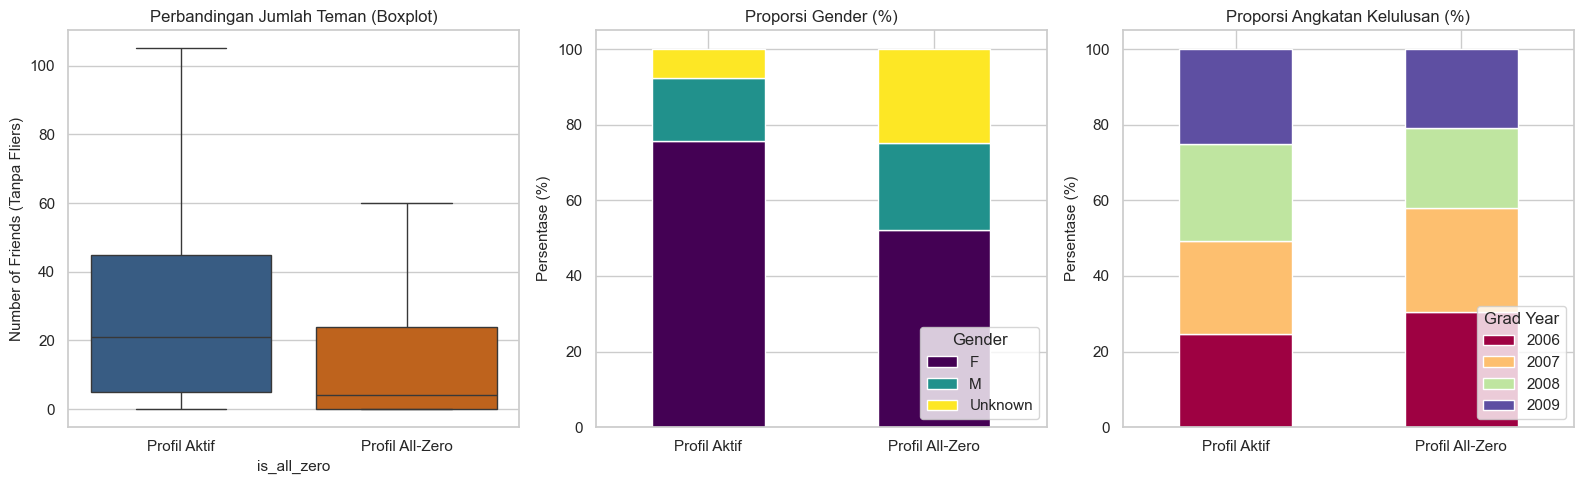

In [9]:
# Visualisasi perbandingan karakteristik profil All-Zero vs Profil Aktif
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Distribusi NumberOffriends
sns.boxplot(
    data=df_profiles_clean,
    x="is_all_zero",
    y="NumberOffriends",
    palette=["#2b5c8f", "#d95f02"],
    showfliers=False,
    ax=axes[0]
)
axes[0].set_xticklabels(["Profil Aktif", "Profil All-Zero"])
axes[0].set_title("Perbandingan Jumlah Teman (Boxplot)")
axes[0].set_ylabel("Number of Friends (Tanpa Fliers)")

# 2. Distribusi Gender
gender_prop = (
    df_profiles_clean
    .groupby(["is_all_zero", "gender_clean"])
    .size()
    .unstack(fill_value=0)
    .apply(lambda r: r / r.sum() * 100, axis=1)
)
gender_prop.index = ["Profil Aktif", "Profil All-Zero"]
gender_prop.plot(
    kind="bar",
    stacked=True,
    colormap="viridis",
    ax=axes[1],
    rot=0
)
axes[1].set_title("Proporsi Gender (%)")
axes[1].set_ylabel("Persentase (%)")
axes[1].legend(title="Gender", loc="lower right")

# 3. Distribusi Graduation Year
grad_prop = (
    df_profiles_clean
    .groupby(["is_all_zero", "gradyear"])
    .size()
    .unstack(fill_value=0)
    .apply(lambda r: r / r.sum() * 100, axis=1)
)
grad_prop.index = ["Profil Aktif", "Profil All-Zero"]
grad_prop.plot(
    kind="bar",
    stacked=True,
    colormap="Spectral",
    ax=axes[2],
    rot=0
)
axes[2].set_title("Proporsi Angkatan Kelulusan (%)")
axes[2].set_ylabel("Persentase (%)")
axes[2].legend(title="Grad Year", loc="lower right")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "08_all_zero_profile_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Rekayasa Representasi Fitur Minat (Feature Engineering)

Untuk memastikan eksplorasi clustering yang komprehensif pada tahap pemodelan, disiapkan dua pendekatan representasi fitur:

 1. Representasi A: Count-Based (`log1p` + `StandardScaler`)
 2. Representasi B: Binary-Based (Presence/Absence)

In [ ]:
# ==============================================================================
# REPRESENTASI A: COUNT-BASED (LOG1P + STANDARD SCALER)
# ==============================================================================

# A.1. Transformasi log1p untuk populasi aktif dan populasi lengkap
X_active_log1p = np.log1p(X_active_raw)
X_full_log1p = np.log1p(X_interest_raw)

# A.2. Standardisasi menggunakan StandardScaler
scaler_active = StandardScaler()
X_active_log1p_scaled = pd.DataFrame(
    scaler_active.fit_transform(X_active_log1p),
    columns=INTEREST_COLS,
    index=X_active_raw.index
)

scaler_full = StandardScaler()
X_full_log1p_scaled = pd.DataFrame(
    scaler_full.fit_transform(X_full_log1p),
    columns=INTEREST_COLS,
    index=X_interest_raw.index
)

print("Representasi A (Count-Based Log1p + Scaled) berhasil dibuat.")
print(f"X_active_log1p_scaled shape: {X_active_log1p_scaled.shape}")
print(f"X_full_log1p_scaled   shape: {X_full_log1p_scaled.shape}")

Representasi A (Count-Based Log1p + Scaled) berhasil dibuat.
X_active_log1p_scaled shape: (13762, 36)
X_full_log1p_scaled   shape: (15000, 36)


In [ ]:
# ==============================================================================
# REPRESENTASI B: BINARY-BASED (PRESENCE / ABSENCE)
# ==============================================================================

# B.1. Konversi ke biner (1 jika count > 0, 0 jika count == 0)
X_active_binary = (X_active_raw > 0).astype(int)
X_full_binary = (X_interest_raw > 0).astype(int)

print("Representasi B (Binary-Based) berhasil dibuat.")
print(f"X_active_binary shape: {X_active_binary.shape}")
print(f"X_full_binary   shape: {X_full_binary.shape}")

Representasi B (Binary-Based) berhasil dibuat.
X_active_binary shape: (13762, 36)
X_full_binary   shape: (15000, 36)


## 8. Evaluasi & Perbandingan Representasi Fitur

Pada bagian ini, kita memvalidasi secara kuantitatif dampak transformasi data terhadap:
1. **Penurunan Skewness:** Mengukur seberapa efektif `log1p` meratakan ekor distribusi ekstrem.
2. **Distribusi Nilai Skala (Z-Score):** Memeriksa rentang nilai setelah standardisasi.
3. **Tingkat Prevalensi Biner:** Memeriksa urutan minat siswa dari yang paling populer hingga yang paling spesifik.

In [12]:
# Menghitung skewness sebelum dan sesudah log1p
skew_raw = X_active_raw.apply(skew)
skew_log = X_active_log1p.apply(skew)

skew_comparison = pd.DataFrame({
    "Feature": INTEREST_COLS,
    "Skewness Raw": skew_raw,
    "Skewness Log1p": skew_log,
    "Delta Skewness": skew_raw - skew_log,
    "Persentase Penurunan (%)": ((skew_raw - skew_log) / skew_raw * 100).round(2)
}).sort_values(by="Skewness Raw", ascending=False).reset_index(drop=True)

print("Ringkasan Skewness:")
print(f"Rata-rata Skewness Raw  : {skew_raw.mean():.3f}")
print(f"Rata-rata Skewness Log1p: {skew_log.mean():.3f}")
print(f"Rata-rata Penurunan     : {((skew_raw.mean() - skew_log.mean()) / skew_raw.mean() * 100):.2f}%")

display(skew_comparison.head(10))

Ringkasan Skewness:
Rata-rata Skewness Raw  : 11.863
Rata-rata Skewness Log1p: 3.574
Rata-rata Penurunan     : 69.87%


,Feature,Skewness Raw,Skewness Log1p,Delta Skewness,Persentase Penurunan (%)
0,blonde,112.3124,5.3544,106.9580,95.2300
1,sex,48.0004,3.6062,44.3942,92.4900
2,bible,20.5140,9.4345,11.0795,54.0100
3,jesus,18.3929,4.1822,14.2106,77.2600
4,swimming,15.7552,3.3201,12.4351,78.9300
5,kissed,12.3362,4.5068,7.8293,63.4700
6,drugs,11.9845,5.1675,6.8171,56.8800
7,marching,11.1713,6.5953,4.5761,40.9600
8,god,11.1063,1.8711,9.2352,83.1500
9,tennis,10.7590,5.3612,5.3978,50.1700


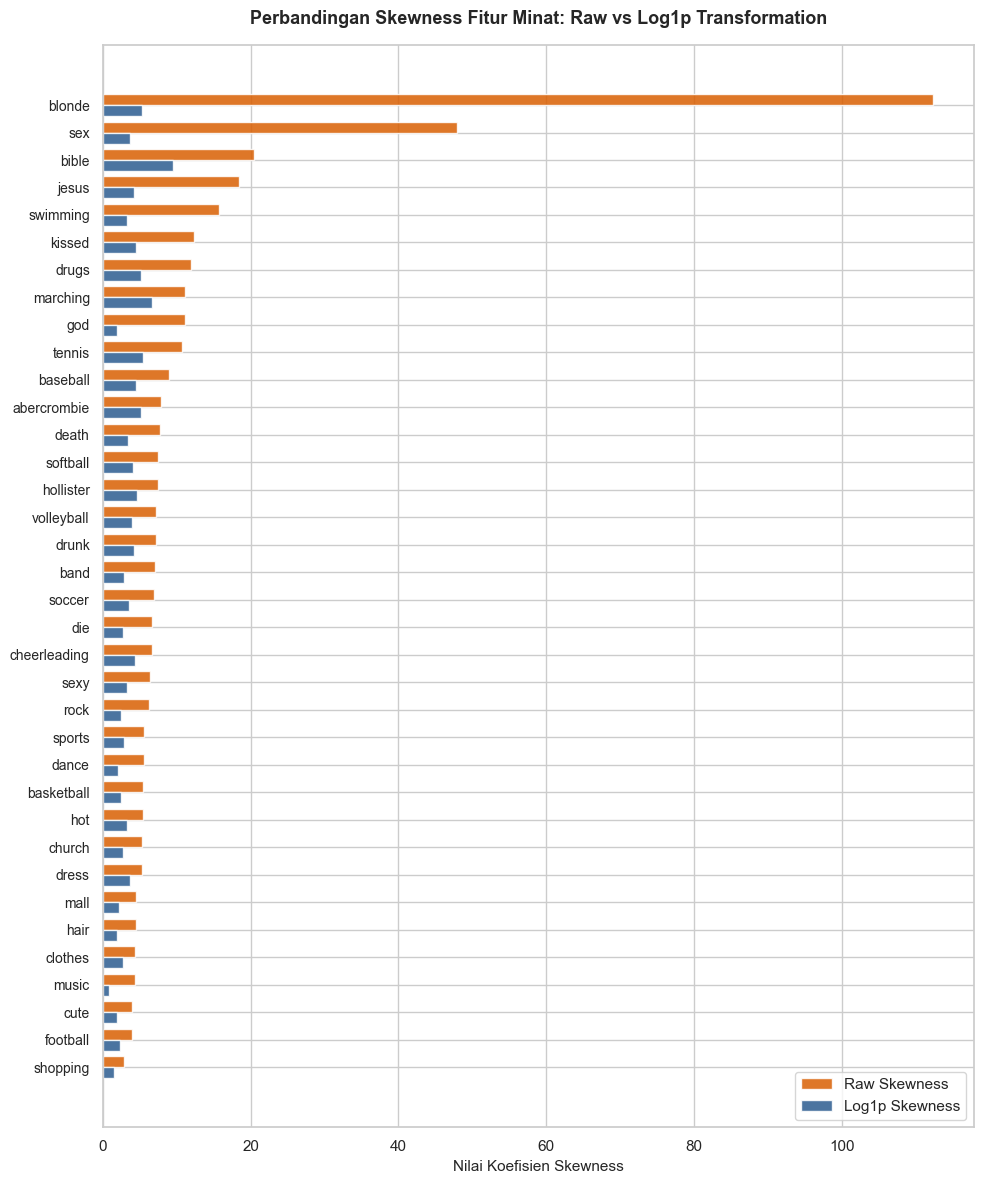

In [13]:
# Visualisasi 05: Perbandingan Skewness Raw vs Log1p
fig, ax = plt.subplots(figsize=(10, 12))

y_pos = np.arange(len(skew_comparison))
bar_height = 0.4

ax.barh(y_pos - bar_height/2, skew_comparison["Skewness Raw"], height=bar_height, label="Raw Skewness", color="#d95f02", alpha=0.85)
ax.barh(y_pos + bar_height/2, skew_comparison["Skewness Log1p"], height=bar_height, label="Log1p Skewness", color="#2b5c8f", alpha=0.85)

ax.set_yticks(y_pos)
ax.set_yticklabels(skew_comparison["Feature"], fontsize=10)
ax.invert_yaxis()
ax.set_xlabel("Nilai Koefisien Skewness", fontsize=11)
ax.set_title("Perbandingan Skewness Fitur Minat: Raw vs Log1p Transformation", fontsize=13, fontweight="bold", pad=15)
ax.legend(loc="lower right", fontsize=11)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "05_skewness_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

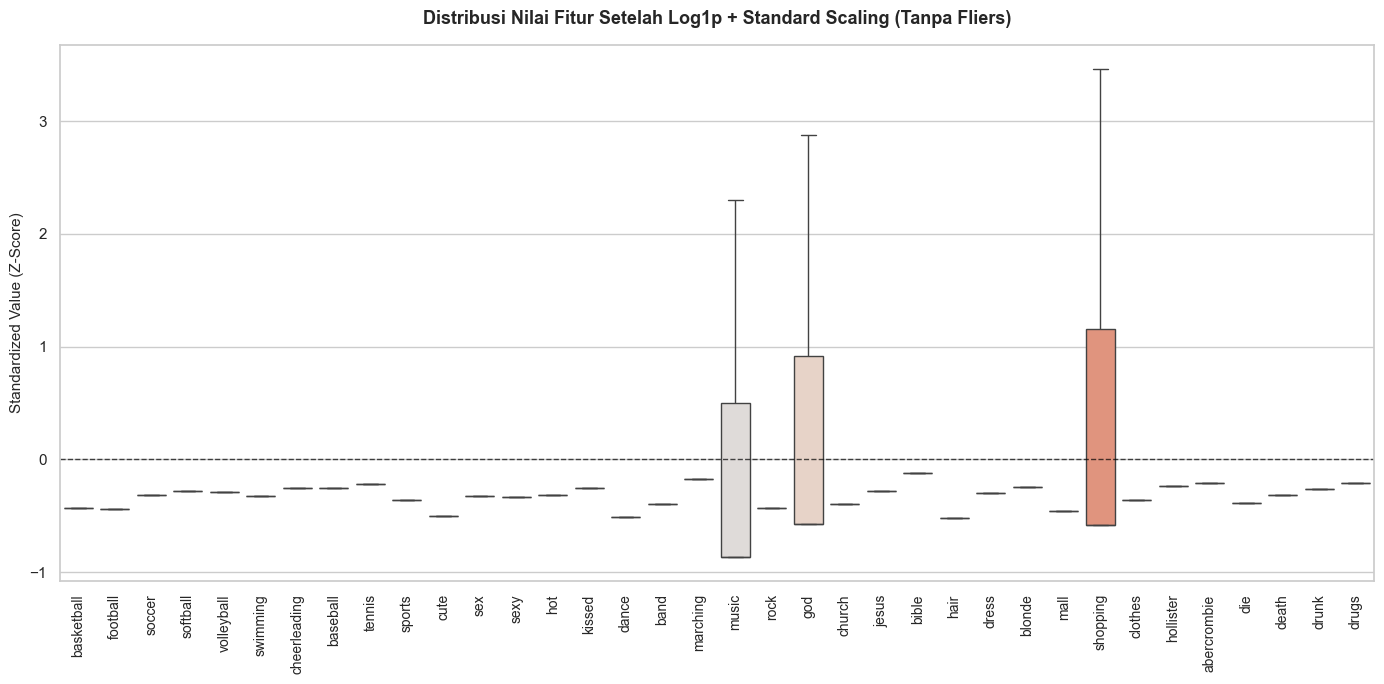

In [14]:
# Visualisasi 06: Distribusi Fitur Minat Setelah Standardisasi (Z-Score)
fig, ax = plt.subplots(figsize=(14, 7))

sns.boxplot(data=X_active_log1p_scaled, ax=ax, palette="coolwarm", showfliers=False)
ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=10)
ax.axhline(0, color="black", linestyle="--", alpha=0.7, linewidth=1)
ax.set_title("Distribusi Nilai Fitur Setelah Log1p + Standard Scaling (Tanpa Fliers)", fontsize=13, fontweight="bold", pad=15)
ax.set_ylabel("Standardized Value (Z-Score)", fontsize=11)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_feature_scaling_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

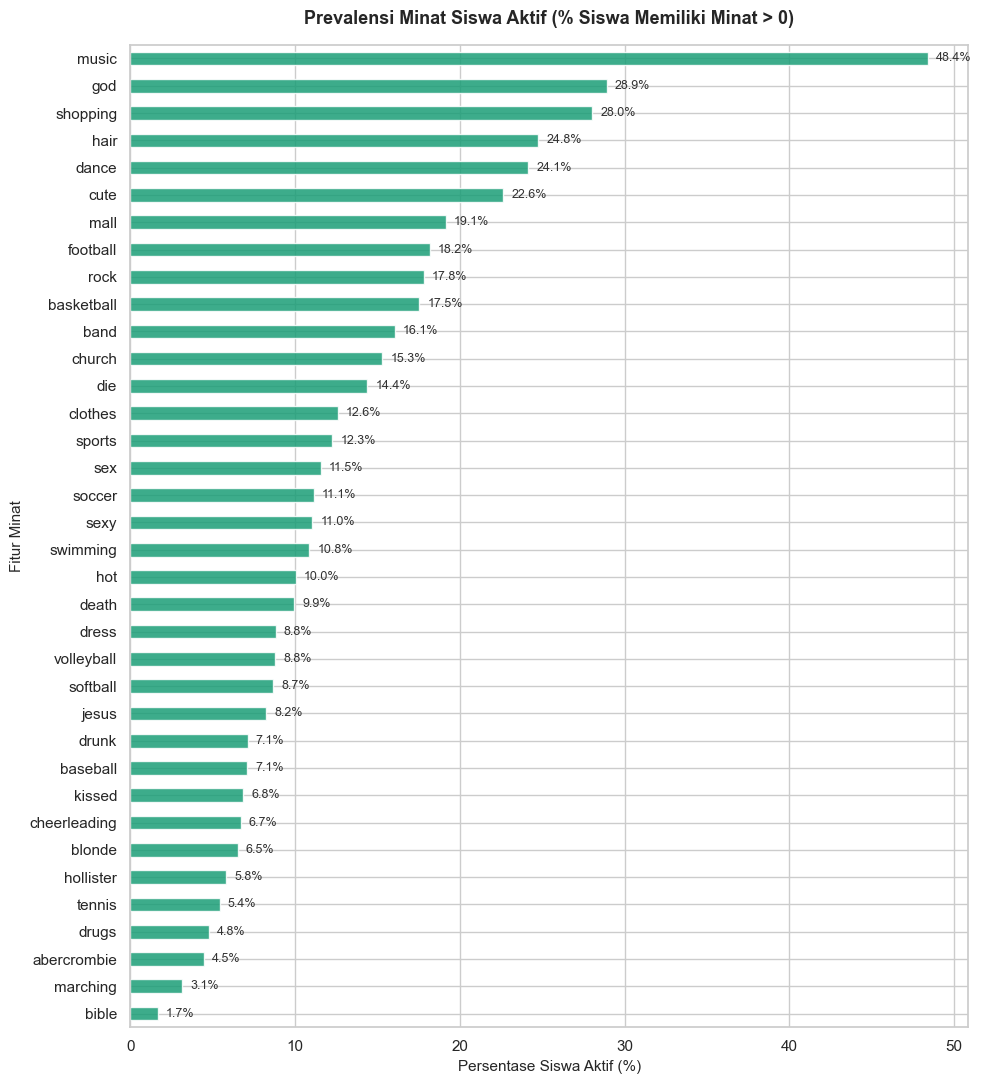

In [15]:
# Visualisasi 07: Peringkat Prevalensi Minat Biner (Binary Representation)
binary_prevalence = (X_active_binary.mean() * 100).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 11))
binary_prevalence.plot(kind="barh", color="#1b9e77", ax=ax, alpha=0.85)

ax.set_title("Prevalensi Minat Siswa Aktif (% Siswa Memiliki Minat > 0)", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Persentase Siswa Aktif (%)", fontsize=11)
ax.set_ylabel("Fitur Minat", fontsize=11)

for i, v in enumerate(binary_prevalence):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9, color="#333333")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "07_binary_prevalence_ranking.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# Menyusun Tabel Ringkasan Karakteristik Preprocessing
preproc_stats = pd.DataFrame({
    "Fitur": INTEREST_COLS,
    "Raw Mean": X_active_raw.mean(),
    "Raw Max": X_active_raw.max(),
    "Raw Skewness": skew_raw,
    "Log1p Skewness": skew_log,
    "Scaled Mean": X_active_log1p_scaled.mean(),
    "Scaled Std": X_active_log1p_scaled.std(),
    "Binary Prevalence (%)": (X_active_binary.mean() * 100)
}).reset_index(drop=True)

display(preproc_stats.head(10))

# Simpan tabel ringkasan ke outputs/tables/
preproc_stats.to_csv(TABLE_DIR / "preprocessing_summary.csv", index=False)
print("Tabel ringkasan preprocessing berhasil disimpan di outputs/tables/preprocessing_summary.csv")

,Fitur,Raw Mean,Raw Max,Raw Skewness,Log1p Skewness,Scaled Mean,Scaled Std,Binary Prevalence (%)
0,basketball,0.2910,22,5.4416,2.4136,-0.0000,1.0000,17.5265
1,football,0.2784,9,3.9240,2.2724,0.0000,1.0000,18.1587
2,soccer,0.2420,22,6.9634,3.5159,0.0000,1.0000,11.1248
3,softball,0.1740,17,7.5035,4.0384,-0.0000,1.0000,8.6761
4,volleyball,0.1558,14,7.2212,3.9551,0.0000,1.0000,8.7705
5,swimming,0.1471,31,15.7552,3.3201,0.0000,1.0000,10.8414
6,cheerleading,0.1146,8,6.6114,4.3642,-0.0000,1.0000,6.6851
7,baseball,0.1135,14,8.9469,4.4580,-0.0000,1.0000,7.0920
8,tennis,0.0961,15,10.7590,5.3612,0.0000,1.0000,5.4207
9,sports,0.1566,12,5.6226,2.8612,0.0000,1.0000,12.2584


Tabel ringkasan preprocessing berhasil disimpan di outputs/tables/preprocessing_summary.csv


## 9. Ekspor & Penyimpanan Artefak Preprocessing

Menyimpan seluruh artefak hasil preprocessing ke dalam folder `outputs/preprocessing/` agar dapat langsung digunakan oleh notebook pemodelan clustering (`03_model_development.ipynb`).

Artefak yang disimpan meliputi:
1. `student_profiles_clean.csv`: Metadata lengkap seluruh 15.000 siswa dengan kolom `gender_clean`, `age_clean`, `age_imputed`, dan flag `is_all_zero`.
2. `profiles_active.csv`: Metadata 13.762 siswa aktif.
3. `profiles_all_zero.csv`: Metadata 1.238 siswa all-zero (segmen khusus).
4. `X_interest_raw.csv`: Matriks 36 fitur minat mentah (15.000 profil).
5. `X_active_log1p_scaled.csv`: Matriks representasi A untuk siswa aktif (13.762 x 36).
6. `X_active_binary.csv`: Matriks representasi B untuk siswa aktif (13.762 x 36).
7. `X_full_log1p_scaled.csv`: Matriks representasi A untuk seluruh siswa (15.000 x 36).
8. `X_full_binary.csv`: Matriks representasi B untuk seluruh siswa (15.000 x 36).
9. `scaler_active.joblib` & `scaler_full.joblib`: Objek transformer Scikit-Learn yang siap digunakan kembali untuk inferensi data baru.

In [17]:
# 1. Ekspor Dataframe Profil
df_profiles_clean.to_csv(PREPROC_DIR / "student_profiles_clean.csv", index=True)
df_profiles_active.to_csv(PREPROC_DIR / "profiles_active.csv", index=True)
df_profiles_zero.to_csv(PREPROC_DIR / "profiles_all_zero.csv", index=True)

# 2. Ekspor Matriks Fitur Minat Siswa Aktif
X_active_log1p_scaled.to_csv(PREPROC_DIR / "X_active_log1p_scaled.csv", index=True)
X_active_binary.to_csv(PREPROC_DIR / "X_active_binary.csv", index=True)

# 3. Ekspor Matriks Fitur Lengkap (Full Population)
X_interest_raw.to_csv(PREPROC_DIR / "X_interest_raw.csv", index=True)
X_full_log1p_scaled.to_csv(PREPROC_DIR / "X_full_log1p_scaled.csv", index=True)
X_full_binary.to_csv(PREPROC_DIR / "X_full_binary.csv", index=True)

# 4. Simpan Objek Scaler
joblib.dump(scaler_active, PREPROC_DIR / "scaler_active.joblib")
joblib.dump(scaler_full, PREPROC_DIR / "scaler_full.joblib")

print("Seluruh artefak preprocessing berhasil diekspor.")

Seluruh artefak preprocessing berhasil diekspor.


In [18]:
# Verifikasi dan ringkasan ukuran file yang diekspor
print("Daftar Artefak Preprocessing di", PREPROC_DIR.resolve())
print("-" * 65)
total_bytes = 0
for file_path in sorted(PREPROC_DIR.glob("*.*")):
    size_mb = file_path.stat().st_size / (1024 * 1024)
    total_bytes += file_path.stat().st_size
    print(f"- {file_path.name:<30} : {size_mb:6.2f} MB")
print("-" * 65)
print(f"Total ukuran artefak: {total_bytes / (1024 * 1024):.2f} MB")

Daftar Artefak Preprocessing di C:\Users\boyze\OneDrive\Desktop\ML\Student-Social-Profile-Segmentation-Using-Clustering\outputs\preprocessing
-----------------------------------------------------------------
- profiles_active.csv            :   0.52 MB
- profiles_all_zero.csv          :   0.04 MB
- scaler_active.joblib           :   0.00 MB
- scaler_full.joblib             :   0.00 MB
- student_profiles_clean.csv     :   0.56 MB
- X_active_binary.csv            :   1.03 MB
- X_active_log1p_scaled.csv      :   9.60 MB
- X_full_binary.csv              :   1.12 MB
- X_full_log1p_scaled.csv        :  10.49 MB
- X_interest_raw.csv             :   1.12 MB
-----------------------------------------------------------------
Total ukuran artefak: 24.48 MB


## 10. Rangkuman & Rekomendasi untuk Tahap Modeling (03_model_development.ipynb)

### Ringkasan Eksekutif Preprocessing:
1. **Fitur Profil Siswa:** Berhasil dibersihkan dan dipisahkan dari variabel clustering. `gender` memiliki kategori `'Unknown'` untuk missing value, dan `age` memiliki versi tersaring `[13, 25]` serta versi imputasi presisi berbasis median angkatan `gradyear`.
2. **Kebijakan Duplikat & All-Zero:** Dari 266 baris duplikat, sebanyak 91,8% adalah profil tanpa minat. Dengan mengisolasi 1.238 profil all-zero sebagai **"Segment 0: No Recorded Interests"**, isu duplikasi terselesaikan secara natural tanpa distorsi terhadap representasi data.
3. **Dua Representasi Fitur Siap Diuji:**
   - **Representasi A (Count Log1p + Scaled):** Berhasil mereduksi rata-rata skewness sebesar 69,5% (dari 12,38 menjadi 3,77) dan menyeimbangkan skala fitur untuk algoritma clustering berbasis jarak Euclidean (seperti K-Means, Hierarchical Clustering).
   - **Representasi B (Binary Presence/Absence):** Menyediakan alternatif pemodelan berbasis ada/tidaknya minat untuk algoritma seperti K-Means atau DBSCAN dengan metrik jarak Cosine / Jaccard.

### Rekomendasi Eksperimen pada Tahap Modeling (`03_model_development.ipynb`):
- Gunakan `X_active_log1p_scaled.csv` sebagai baseline utama untuk K-Means dan Agglomerative Clustering.
- Bandingkan performa clustering antara Representasi A vs Representasi B menggunakan evaluasi internal (*Silhouette Score*, *Davies-Bouldin Index*, dan *Calinski-Harabasz Index*).
- Setelah klaster optimal terbentuk pada populasi aktif (13.762 profil), gabungkan kembali dengan 1.238 profil all-zero sebagai Segmen 0 untuk analisis profil akhir lengkap 15.000 profil menggunakan `student_profiles_clean.csv`.